<a href="https://colab.research.google.com/github/barajascamposluisjavier-ship-it/colab-analisis-acciones/blob/main/Analisis_acciones_ALUMNO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRACTICA 2. ANÁLISIS DE ACCIONES (VISUALIZACIÓN DE DATOS)**

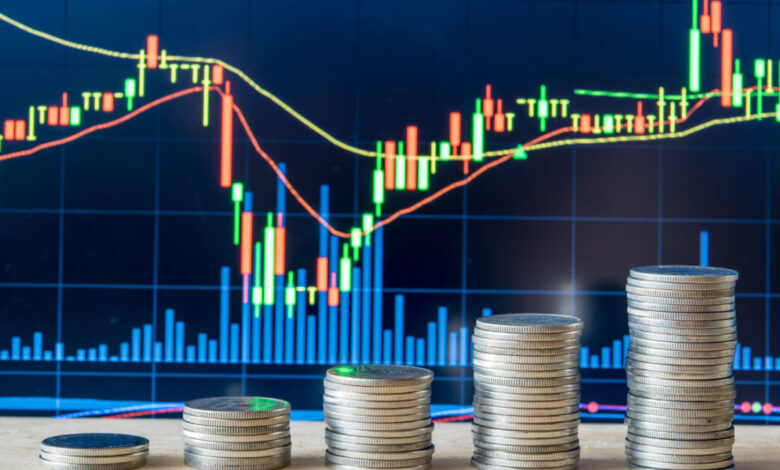

# **Descripción del proyecto**

En este proyecto, visualizaremos los precios de las acciones usando Seaborn y Matplotlib. Se consideran 4 acciones, incluidas JP Morgan Chase (JP), Procter and Gamble (P&G) (PG), Apple (AAPL) y United Airlines (UAL).

Usando el conjunto de datos stock_daily_prices.csv y stocks_daily_returns.csv incluidos en el Classroom del curso, haz lo siguiente:

1.   Importa las lbrerías que utilizarás en este proyecto.
2.   Importa ambos conjuntos de datos usando Pandas.
3.   Realiza un análisis exploratorio de los datos (EDA) básico donde muestres los primeros y últimos 10 registros, que verifiques el tipo de datos que tiene el dataset, que verifiques la cantidad de datos nulos que contiene el dataset.
4.   Calcula el precio promedio, el mínimo y máximo de cada característica de los datasets.
5.   Representar la matriz de correlaciones para los datasets.
6.   Define una función para convertir los valores del dataset acciones (que actualmente estan en dolares a pesos mexicanos, considerando una tasa de 19.36 pesos por dolar). Agrega cada conversión en una nueva columna.
7.   Con Matplotlib, representa diagramas de líneas que muestren los precios diarios de las 4 acciones en una sola cifra
8. Con Matplotlib, representa los 4 precios diarios de acciones en varias suplots.
9. Usando Matplotlib, representa los 4 plots en subplots una al lado de la otra (todas las figuras en una fila).
10. Con Matplotlib, representa el diagrama de dispersión entre los rendimientos diarios de Apple y JP Morgan.
11. Utilizando Seaborn, representa un diagrama de dispersión similar entre los rendimientos diarios de Apple y JP Morgan.
12. Supon que decides volverse alcista sobre AAPL y asignas el 70% de sus activos. También decides dividir en partes iguales el resto de sus activos en otras acciones (JPM, PG y UAL). Con Matplotlib, representa un gráfico circular que muestre estas asignaciones. Utiliza el atributo 'explode' para aumentar la separación entre AAPL y el resto de la cartera.
13. Usando Matplotlib, representa el histograma para los retornos de United Airlines y P&G usando 40 divisiones con color rojo. Muestra la media y la desviación estándar para ambas acciones en la parte superior de la figura. ¿Qué concluyes de este gráfico?
14. Con Seaborn, representa un mapa de calor que muestre las correlaciones entre los rendimientos diarios de las acciones. Comente la correlación entre UAL y P&G.
15. Representa un gráfico 3D que muestre todos los retornos diarios de JPM, AAPL y UAL [Se requiere investigación externa].
16.   Haz el escalamiento de todas las características del dataset acciones utilizando estandarización de datos.
17.   Escala todas las características del dataset rendimientos utilizando la normalización.
18.  Con Matplotlib, representa diagramas de líneas que muestren los precios diarios de las 4 acciones en una sola cifra, comparalos con los gráfico que habías realizado antes.


## **1.- IMPORTAR LIBRERÍAS**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [ ]:
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

## **2.- IMPORTAR DATOS**

In [ ]:
#uno con precios diarios y otro con rendimientos diarios de las acciones.
prices_df = pd.read_csv('P2-stocks_daily_prices.csv')
returns_df = pd.read_csv('P2-stocks_daily_returns.csv')

## **3.- ANÁLISIS EXPLORATORIO DE DATOS**

In [ ]:
#Muestra 10 registros del dataset de precios
prices_df.head(10)

,Date,AAPL,JPM,PG,UAL
0,1/2/2008,5.949703,29.448614,47.058838,29.915234
1,1/3/2008,5.952452,29.246094,47.058838,29.690800
2,1/4/2008,5.498071,28.582682,46.870098,31.000002
3,1/7/2008,5.424478,28.868999,47.175980,29.180000
4,1/8/2008,5.229351,27.723747,47.299629,24.389999
5,1/9/2008,5.478222,28.114801,47.208511,26.030001
6,1/10/2008,5.436081,28.862019,47.169464,32.189999
7,1/11/2008,5.273324,28.533800,45.672649,32.070000
8,1/14/2008,5.459290,28.882969,45.744232,32.930000
9,1/15/2008,5.161868,27.353619,45.360241,34.570000


In [ ]:
# Últimos 10 registros del dataset precio
prices_df.tail(10)

,Date,AAPL,JPM,PG,UAL
3632,6/6/2022,146.139999,129.729996,145.320007,44.759998
3633,6/7/2022,148.710007,130.070007,146.940002,46.450001
3634,6/8/2022,147.960007,128.000000,145.110001,44.599998
3635,6/9/2022,142.639999,125.309998,142.490005,42.700001
3636,6/10/2022,137.130005,119.550003,141.949997,41.160000
3637,6/13/2022,131.880005,115.989998,138.149994,37.020000
3638,6/14/2022,132.759995,114.059998,133.839996,36.990002
3639,6/15/2022,135.429993,115.410004,132.509995,37.889999
3640,6/16/2022,130.059998,113.430000,133.320007,34.779999
3641,6/17/2022,131.559998,113.029999,132.360001,36.279999


In [ ]:
prices_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3642 entries, 0 to 3641
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    3642 non-null   object 
 1   AAPL    3642 non-null   float64
 2   JPM     3642 non-null   float64
 3   PG      3642 non-null   float64
 4   UAL     3642 non-null   float64
dtypes: float64(4), object(1)
memory usage: 142.4+ KB


In [ ]:
# nulos en el dataset de precios
prices_df.isnull().sum()

,0
Date,0
AAPL,0
JPM,0
PG,0
UAL,0


In [ ]:
# Primeros 10 registros de rendimientos
returns_df.head(10)

,Date,AAPL,JPM,PG,UAL
0,1/2/2008,0.000000,0.000000,0.000000,0.000000
1,1/3/2008,0.046203,-0.687708,0.000000,-0.750233
2,1/4/2008,-7.633517,-2.268378,-0.401072,4.409454
3,1/7/2008,-1.338518,1.001718,0.652615,-5.870973
4,1/8/2008,-3.597157,-3.967066,0.262103,-16.415356
5,1/9/2008,4.759115,1.410539,-0.192640,6.724073
6,1/10/2008,-0.769237,2.657736,-0.082712,23.664993
7,1/11/2008,-2.994012,-1.137199,-3.173271,-0.372783
8,1/14/2008,3.526524,1.223702,0.156730,2.681636
9,1/15/2008,-5.447997,-5.294990,-0.839431,4.980259


In [ ]:
# ultimos 10 registros de rendimientos
returns_df.tail(10)

,Date,AAPL,JPM,PG,UAL
3632,6/6/2022,0.522764,-0.330369,-0.390700,0.742737
3633,6/7/2022,1.758593,0.262092,1.114778,3.775698
3634,6/8/2022,-0.504337,-1.591456,-1.245407,-3.982782
3635,6/9/2022,-3.595571,-2.101564,-1.805523,-4.260085
3636,6/10/2022,-3.862868,-4.596596,-0.378980,-3.606559
3637,6/13/2022,-3.828484,-2.977838,-2.677001,-10.058308
3638,6/14/2022,0.667265,-1.663937,-3.119796,-0.081034
3639,6/15/2022,2.011147,1.183593,-0.993725,2.433084
3640,6/16/2022,-3.965145,-1.715625,0.611284,-8.207972
3641,6/17/2022,1.153314,-0.352642,-0.720077,4.312824


In [ ]:
returns_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3642 entries, 0 to 3641
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    3642 non-null   object 
 1   AAPL    3642 non-null   float64
 2   JPM     3642 non-null   float64
 3   PG      3642 non-null   float64
 4   UAL     3642 non-null   float64
dtypes: float64(4), object(1)
memory usage: 142.4+ KB


In [ ]:
# nulos en el dataset de rendimientos
returns_df.isnull().sum()

,0
Date,0
AAPL,0
JPM,0
PG,0
UAL,0


# **4.- PRECIOS MEDIOS**

In [ ]:
#calcular precio promedio de cada activo
prices_df.select_dtypes(include='number').mean()

,0
AAPL,39.648625
JPM,64.927239
PG,73.729653
UAL,43.183288


In [ ]:
prices_df.select_dtypes(include='number').min()

,0
AAPL,2.387943
JPM,11.545819
PG,29.637867
UAL,3.130000


In [ ]:
# precio máximo de cada activo
prices_df.select_dtypes(include='number').max()

,0
AAPL,181.511704
JPM,169.500061
PG,163.410004
UAL,96.699997


In [ ]:
returns_df.select_dtypes(include='number').mean()

,0
AAPL,0.105180
JPM,0.069331
PG,0.035579
UAL,0.098866


In [ ]:
#rendimiento mínimo de cada activo
returns_df.select_dtypes(include='number').min()

,0
AAPL,-17.919513
JPM,-20.727418
PG,-8.737353
UAL,-36.770882


In [ ]:
#rendimiento máximo de cada activo
returns_df.select_dtypes(include='number').max()

,0
AAPL,13.904950
JPM,25.096737
PG,12.009046
UAL,68.537079


# **5.- MATRIZ DE CORRELACIÓN**

<Axes: >

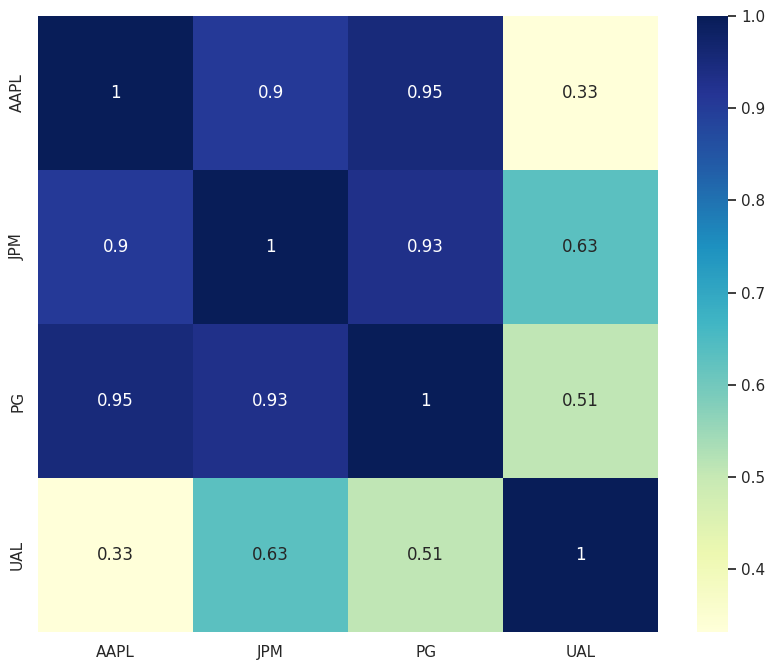

In [ ]:
#matriiz de correlacion precios
correlations = prices_df.corr(numeric_only=True)
f, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlations, annot=True, cmap="YlGnBu")

<Axes: >

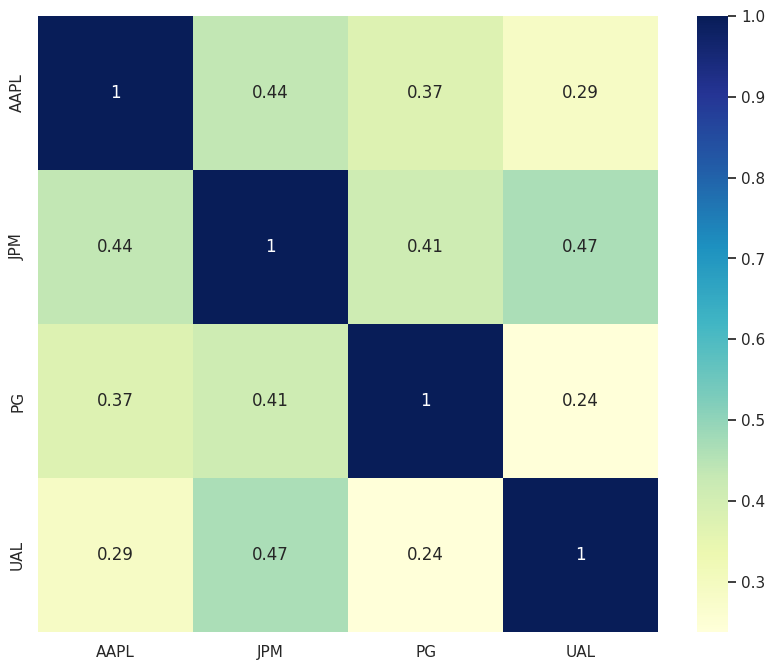

In [ ]:
#correlación rendimientos
correlations = returns_df.corr(numeric_only=True)
f, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlations, annot=True, cmap="YlGnBu")

# **6.- FUNCIÓN DE CONVERSIÓN**

In [ ]:
# convertir USD a MXN
def convertir_usd_a_mxn(df, tasa_cambio=19):
  df_convertido = df.copy()
  columnas_acciones = ['AAPL', 'JPM', 'PG', 'UAL']
  for accion in columnas_acciones:
    df_convertido[f'{accion}_MXN'] = df_convertido[accion] * tasa_cambio
  return df_convertido;
prices_df = convertir_usd_a_mxn(prices_df);
prices_df.head()

,Date,AAPL,JPM,PG,UAL,AAPL_MXN,JPM_MXN,PG_MXN,UAL_MXN
0,1/2/2008,5.949703,29.448614,47.058838,29.915234,113.044361,559.523668,894.117920,568.389439
1,1/3/2008,5.952452,29.246094,47.058838,29.690800,113.096591,555.675781,894.117920,564.125194
2,1/4/2008,5.498071,28.582682,46.870098,31.000002,104.463344,543.070952,890.531864,589.000036
3,1/7/2008,5.424478,28.868999,47.175980,29.180000,103.065083,548.510990,896.343613,554.420006
4,1/8/2008,5.229351,27.723747,47.299629,24.389999,99.357670,526.751198,898.692955,463.409988


# **7.- DIAGRAMAS DE LÍNEAS**

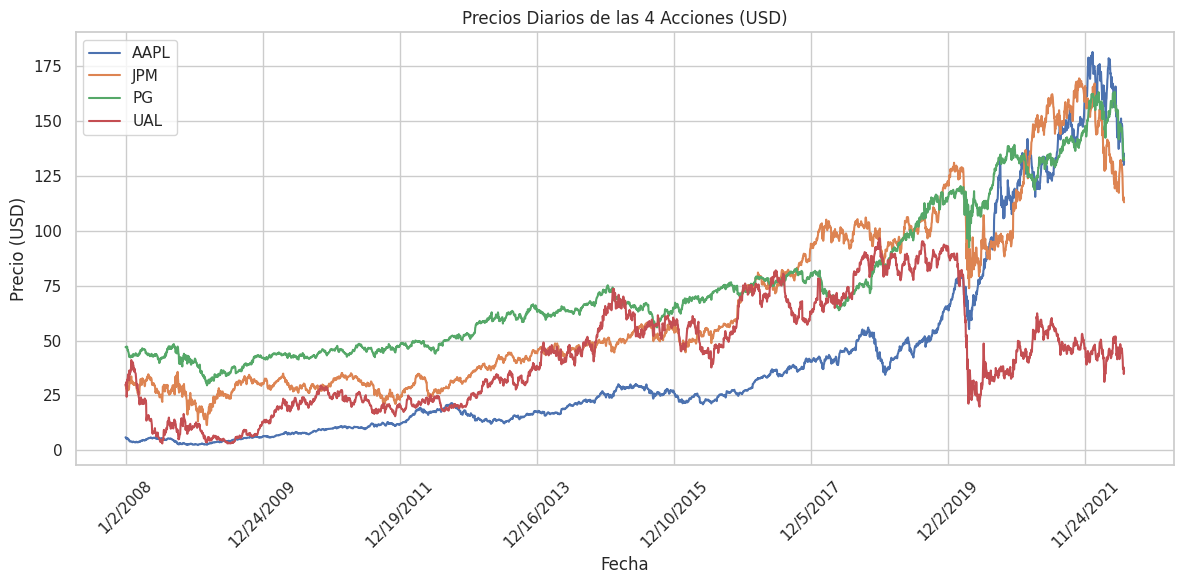

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(prices_df['Date'], prices_df['AAPL'], label='AAPL')
plt.plot(prices_df['Date'], prices_df['JPM'], label='JPM')
plt.plot(prices_df['Date'], prices_df['PG'], label='PG')
plt.plot(prices_df['Date'], prices_df['UAL'], label='UAL')

plt.title('Precios Diarios de las 4 Acciones (USD)')
plt.xlabel('Fecha')
plt.ylabel('Precio (USD)')
plt.xticks(prices_df['Date'][::500], rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# **8.- REPRESENTACIÓN DE SUBPLOTS MÚLTIPLES**

Text(0.5, 1.0, 'United Airlines (UAL)')

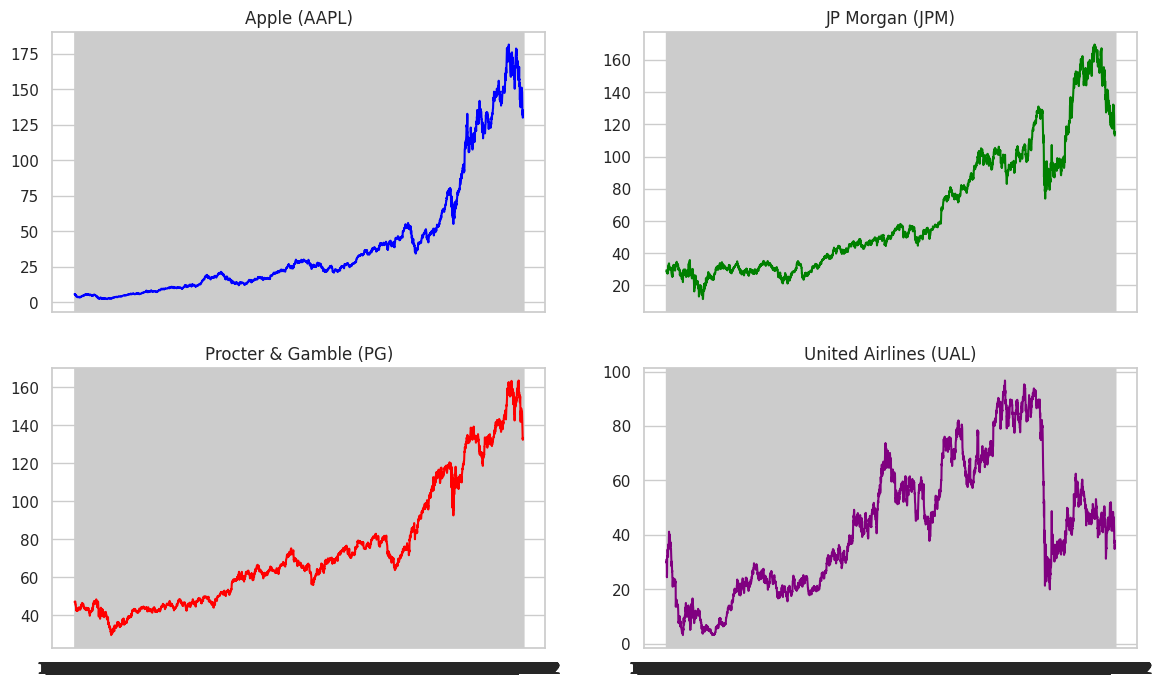

In [ ]:
# Crear subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

axes[0, 0].plot(prices_df['Date'], prices_df['AAPL'], color='blue')
axes[0, 0].set_title('Apple (AAPL)')

axes[0, 1].plot(prices_df['Date'], prices_df['JPM'], color='green')
axes[0, 1].set_title('JP Morgan (JPM)')

axes[1, 0].plot(prices_df['Date'], prices_df['PG'], color='red')
axes[1, 0].set_title('Procter & Gamble (PG)')

axes[1, 1].plot(prices_df['Date'], prices_df['UAL'], color='purple')
axes[1, 1].set_title('United Airlines (UAL)')

# **9.- REPRESENTACIÓN DE SUBPLOTS LATERALES**

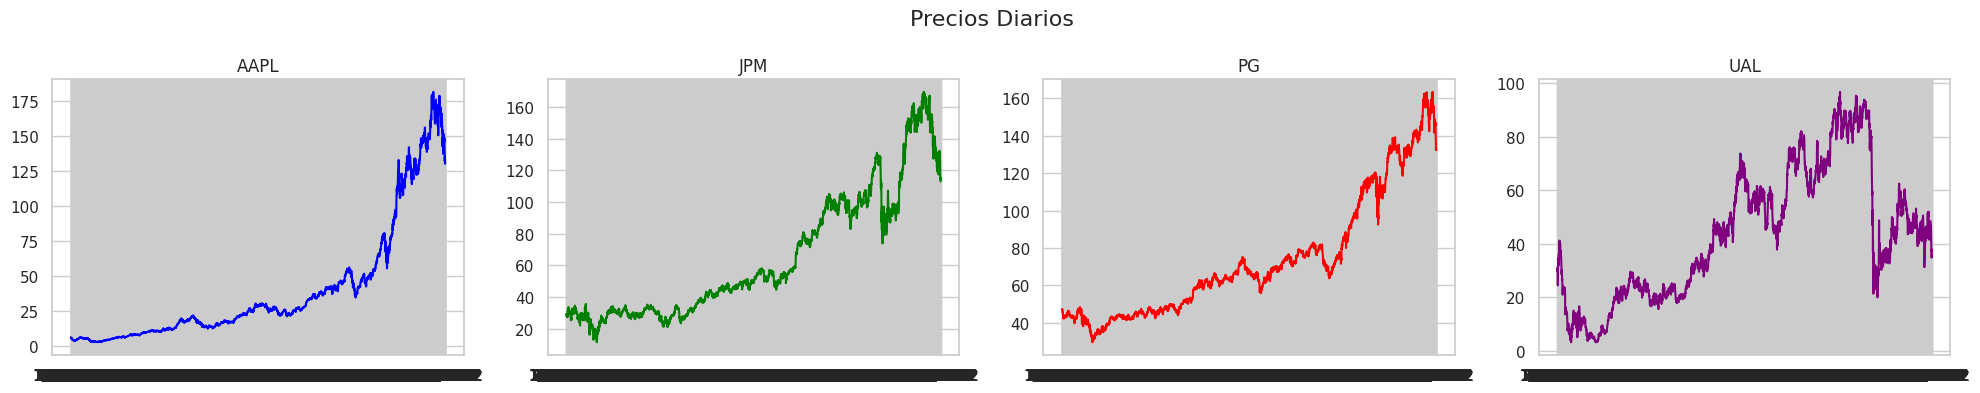

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharex=True)

axes[0].plot(prices_df['Date'], prices_df['AAPL'], color='blue')
axes[0].set_title('AAPL')

axes[1].plot(prices_df['Date'], prices_df['JPM'], color='green')
axes[1].set_title('JPM')

axes[2].plot(prices_df['Date'], prices_df['PG'], color='red')
axes[2].set_title('PG')

axes[3].plot(prices_df['Date'], prices_df['UAL'], color='purple')
axes[3].set_title('UAL')

plt.suptitle('Precios Diarios', fontsize=16)
plt.tight_layout()
plt.show()

# **10.- REPRESENTACIÓN DE DIAGRAMA DE DISPERSIÓN**

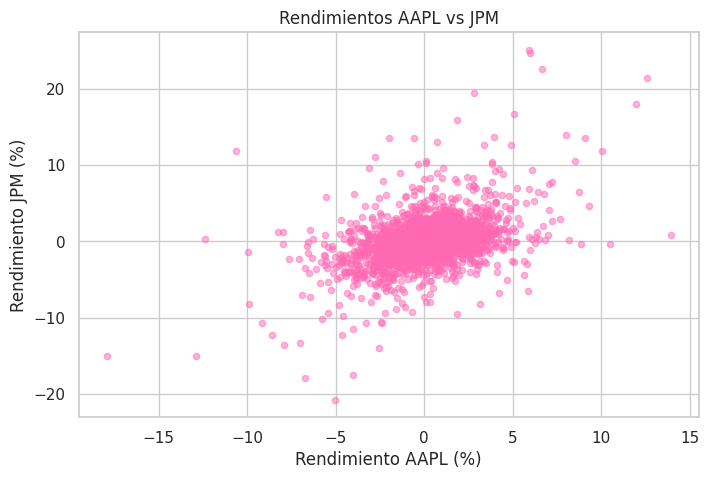

In [ ]:
returns_df.plot.scatter('AAPL', 'JPM', grid=True, figsize=(8, 5), color='hotpink', alpha=0.5)
plt.title('Rendimientos AAPL vs JPM')
plt.xlabel('Rendimiento AAPL (%)')
plt.ylabel('Rendimiento JPM (%)')
plt.show()

# **11.- DIAGRAMA DE DISPERSIÓN CON SEABORN**

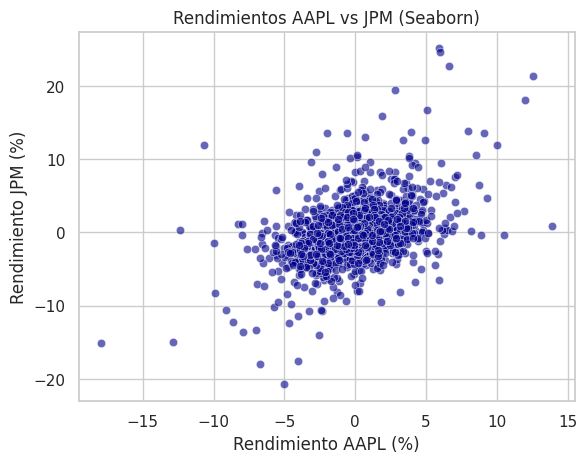

In [ ]:
# Diagrama de dispersión Apple y JP Morgan
sns.scatterplot(x='AAPL', y='JPM', data=returns_df, alpha=0.6, color='darkblue')
plt.title('Rendimientos AAPL vs JPM (Seaborn)')
plt.xlabel('Rendimiento AAPL (%)')
plt.ylabel('Rendimiento JPM (%)')
plt.show()

# **12.- GRÁFICO DE PASTEL**

In [ ]:
my_data = {'Asignacion %': [70, 10, 10, 10]}
explode = (0.1, 0, 0, 0)

acciones_df = pd.DataFrame(data=my_data, index=['AAPL', 'JPM', 'PG', 'UAL'])

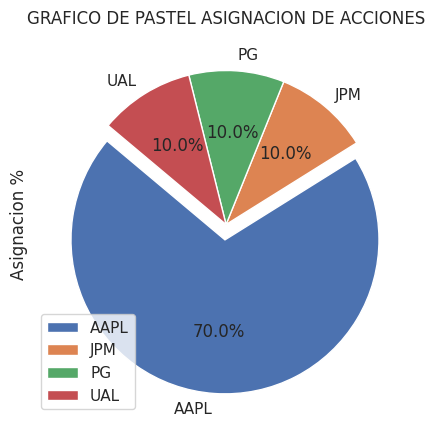

In [ ]:
acciones_df.plot.pie(
    y='Asignacion %',
    explode=explode,
    figsize=(5, 5),
    autopct='%1.1f%%',
    startangle=140,
)
plt.title('GRAFICO DE PASTEL ASIGNACION DE ACCIONES')
plt.show()

# **13.- REPRESENTACIÓN DE HISTOGRAMA**

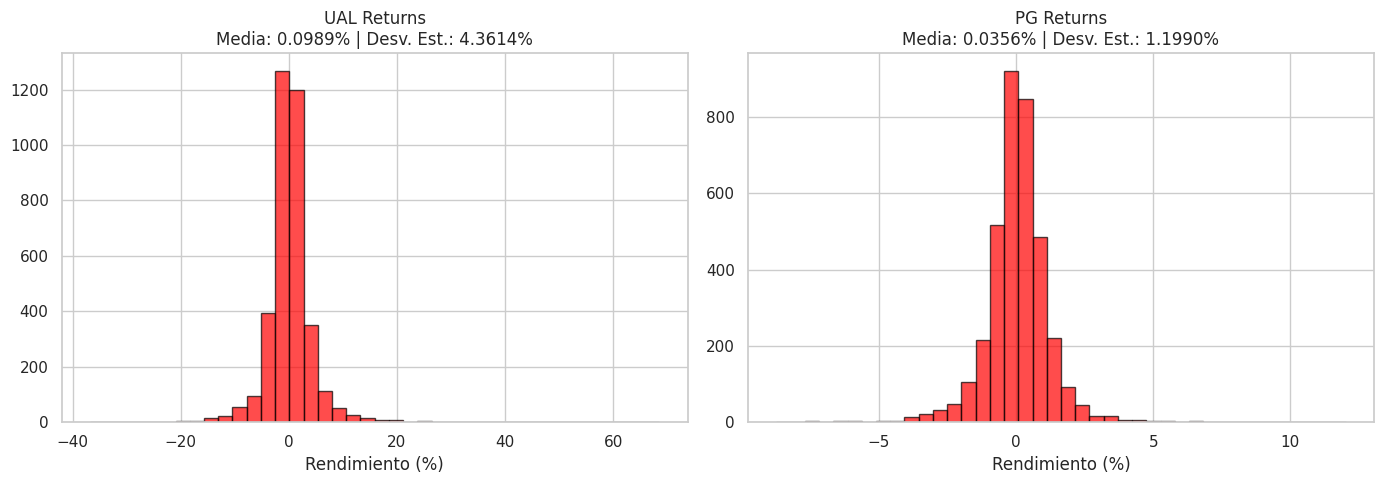

In [ ]:
# rendimientos diarios de UAL y PG en40 subplots roojos iguales
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(returns_df['UAL'], bins=40, color='red', alpha=0.7, edgecolor='black')
axes[0].set_title(f"UAL Returns\nMedia: {returns_df['UAL'].mean():.4f}% | Desv. Est.: {returns_df['UAL'].std():.4f}%")
axes[0].set_xlabel('Rendimiento (%)')

axes[1].hist(returns_df['PG'], bins=40, color='red', alpha=0.7, edgecolor='black')
axes[1].set_title(f"PG Returns\nMedia: {returns_df['PG'].mean():.4f}% | Desv. Est.: {returns_df['PG'].std():.4f}%")
axes[1].set_xlabel('Rendimiento (%)')

plt.tight_layout()
plt.show()

# Conclusión del gráfico
UAL: Muestra una mayor dispersión, lo que indica alta volatilidad y mayor riesgo en sus rendimientos diarios debido a la alta sensibilidad del sector aeronáutico a factores externos

PG: Presenta una distribución estrecha y concentrada cerca de la media, reflejando estabilidad y bajo riesgo gracias a ser un negocio de consumo masivo defensivo.


# **14.- REPRESENTACIÓN DE MAPA DE CALOR**

In [ ]:
#matriz de correlación de los rendimientos diarios
cm = returns_df[['AAPL', 'JPM', 'PG', 'UAL']].corr()

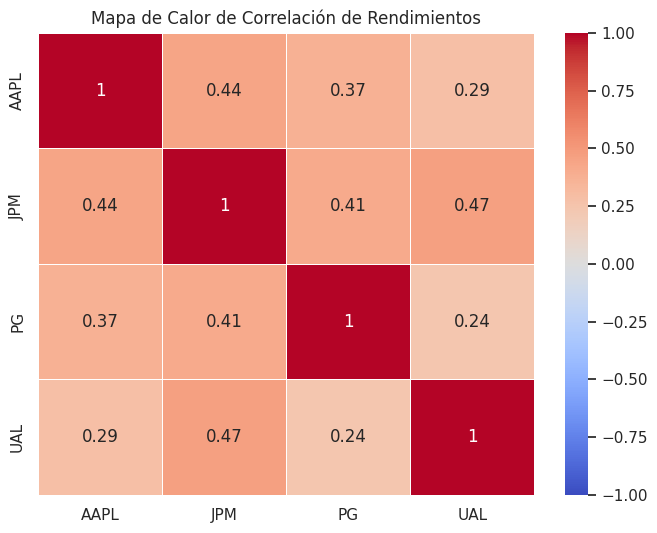

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Mapa de Calor de Correlación de Rendimientos')
plt.show()

# **15.- REPRESENTACIÓN DE GRÁFICO 3D**

# Investigacion

Un gráfico normal en 2D se queda corto si quieres ver cómo se comportan tres acciones (JPM, AAPL y UAL) al mismo tiempo, porque solo te deja comparar dos variables.

Para armar una gráfica en 3D, usamos el módulo mpl_toolkits.mplot3d que ya viene incluido en Matplotlib. Básicamente, esto le agrega un motor de proyección 3D a las gráficas de toda la vida usando la clase Axes3D.

Librería principal: matplotlib.pyplot

Módulo 3D: mpl_toolkits.mplot3d (es el que te da la opción de usar '3d')

Función para graficar: ax.scatter(), donde mandas cada acción a un eje diferente:

Eje X: Rendimientos de JPMorgan Chase (JPM)

Eje Y: Rendimientos de Apple (AAPL)

Eje Z: Rendimientos de United Airlines (UAL)

Con esto se arman nubes de puntos en el espacio que te tiran paro para ver más rápido si se mueven juntas, si hay mucha volatilidad en grupo o si saltan datos raros (outliers) entre los tres sectores al mismo tiempo.

In [ ]:
#módulo para 3d en Matplotlib
from mpl_toolkits.mplot3d import Axes3D

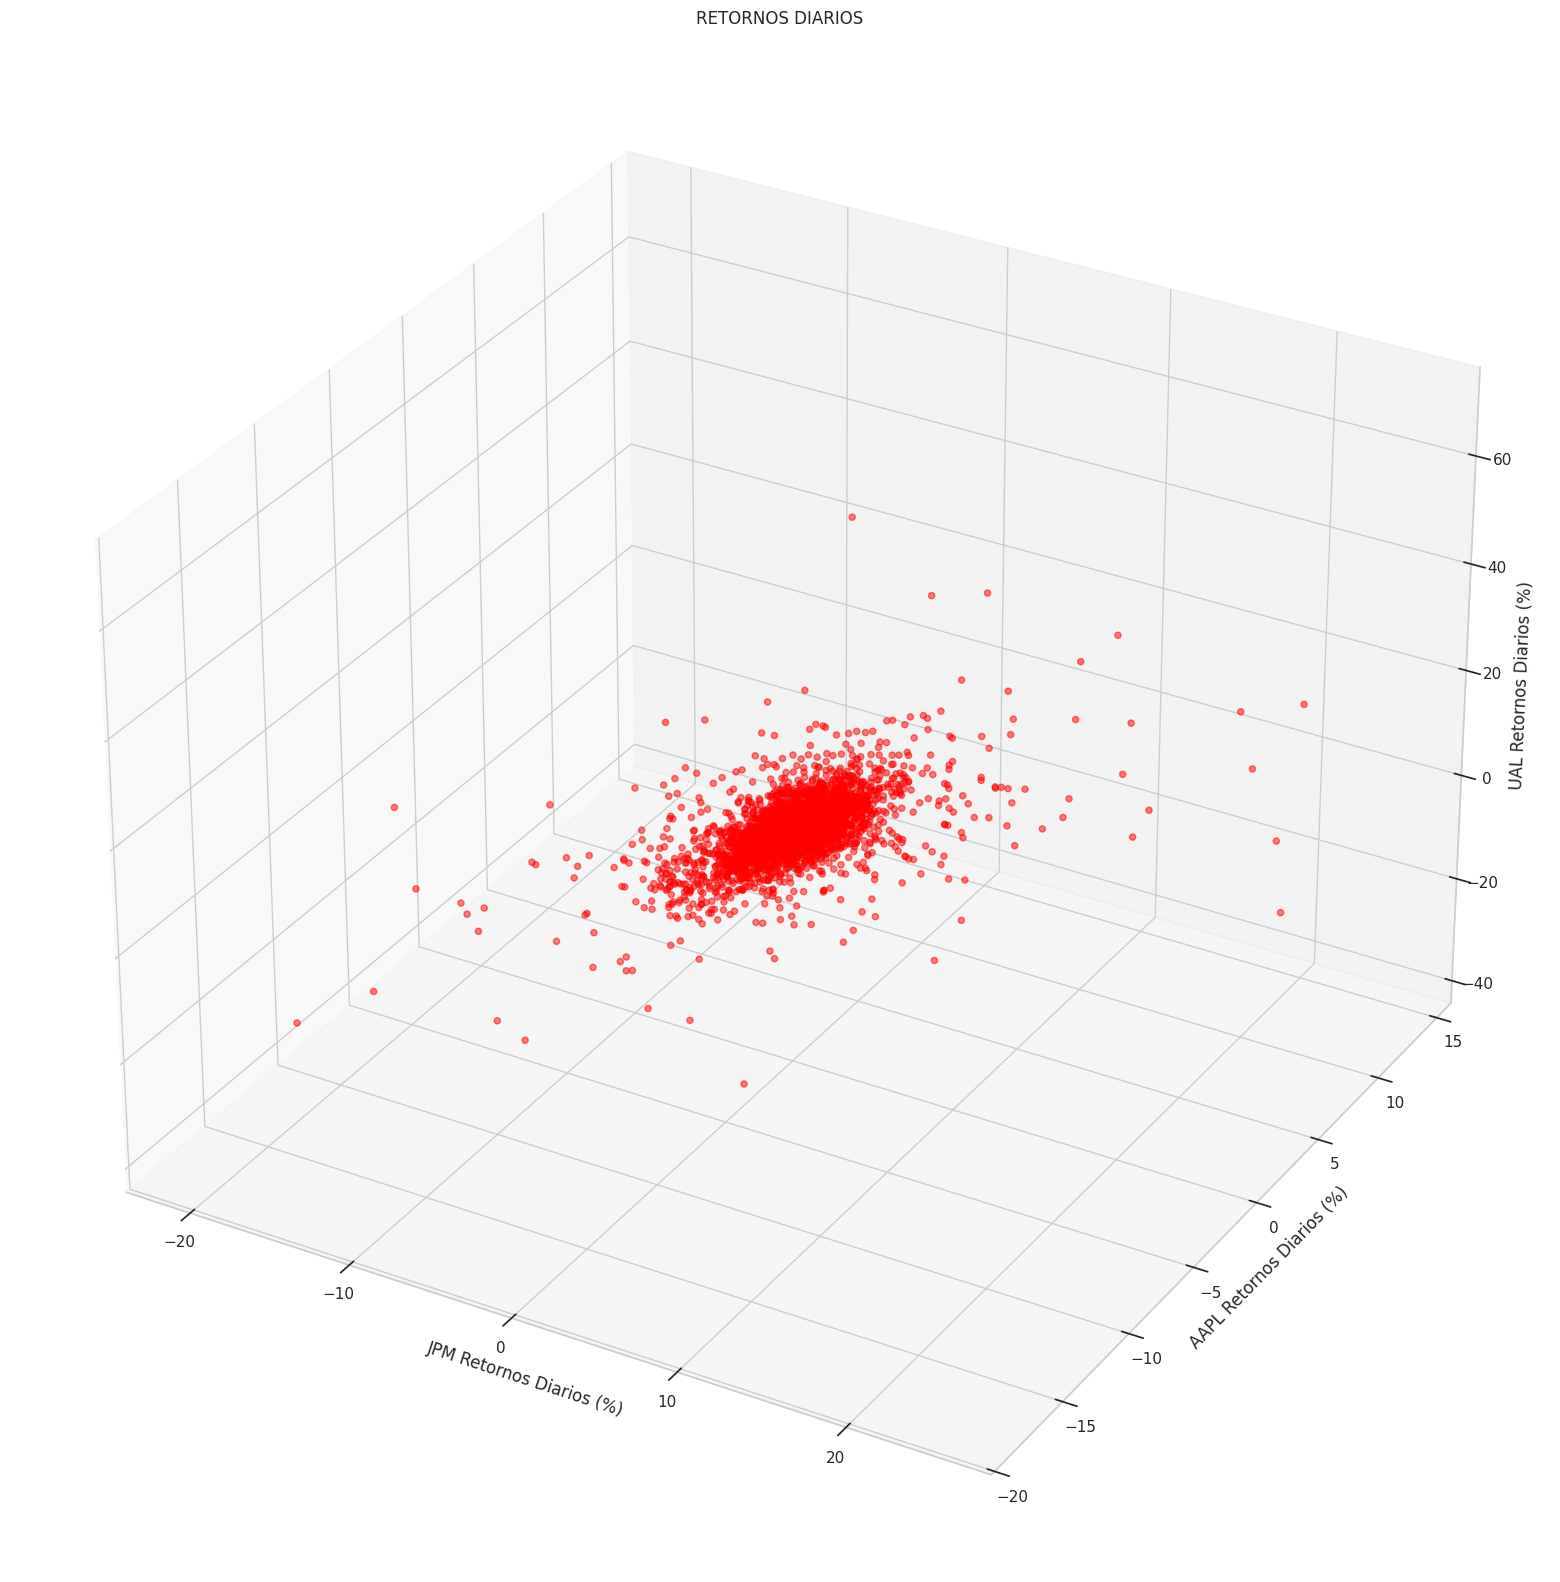

In [ ]:
fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(returns_df['JPM'], returns_df['AAPL'], returns_df['UAL'], c='red', marker='o', alpha=0.5)

# Etiquetads
ax.set_xlabel('JPM Retornos Diarios (%)')
ax.set_ylabel('AAPL Retornos Diarios (%)')
ax.set_zlabel('UAL Retornos Diarios (%)')
ax.set_title('RETORNOS DIARIOS')

plt.show()

# **16.- ESTANDARIZACIÓN DE DATOS**

In [ ]:
features = ['AAPL', 'JPM', 'PG', 'UAL']

scaler_std = StandardScaler()

# almacenar los datos estandarizados
prices_scaled_df = prices_df.copy()
prices_scaled_df[features] = scaler_std.fit_transform(prices_df[features])

# **17.- NORMALIZACIÓN DE DATOS**

In [ ]:
features = ['AAPL', 'JPM', 'PG', 'UAL']

# normalizar al rango [0, 1]
scaler_minmax = MinMaxScaler()

# almacemar datos normalizados
returns_scaled_df = returns_df.copy()
returns_scaled_df[features] = scaler_minmax.fit_transform(returns_df[features])

# **18.- DIAGRAMA DE LÍNEAS CON MATPLOTLIB**

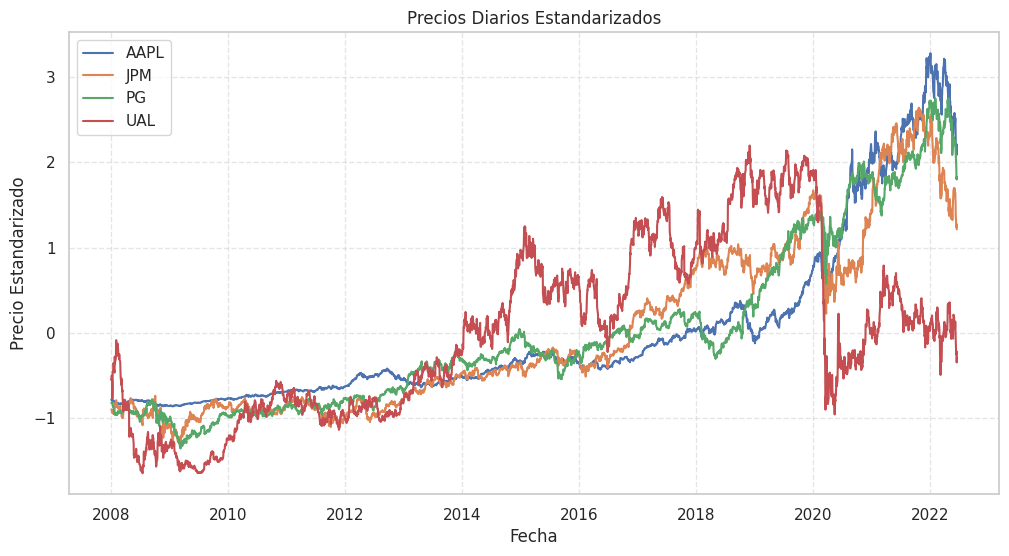

In [ ]:
prices_scaled_df['Date'] = pd.to_datetime(prices_scaled_df['Date'])

#graficar los precios diarios estandarizados
plt.figure(figsize=(12, 6))

plt.plot(prices_scaled_df['Date'], prices_scaled_df['AAPL'], label='AAPL')
plt.plot(prices_scaled_df['Date'], prices_scaled_df['JPM'], label='JPM')
plt.plot(prices_scaled_df['Date'], prices_scaled_df['PG'], label='PG')
plt.plot(prices_scaled_df['Date'], prices_scaled_df['UAL'], label='UAL')

plt.title('Precios Diarios Estandarizados')
plt.xlabel('Fecha')
plt.ylabel('Precio Estandarizado')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

# Comparación entre el Punto 18 y el Punto 7

Gráfico del Punto 7 (Precios originales en USD): Como cada acción maneja precios totalmente distintos (una puede costar 30 dólares y otra 150), la que tiene el valor más alto acapara toda la gráfica en el eje Y. Eso hace que las líneas de las acciones más "baratas" se aplasten y casi ni se distingan, impidiendo ver sus cambios reales.

Gráfico del Punto 18 (Precios estandarizados): Al hacer el cálculo (restar la media y dividir entre la desviación estándar), todas las acciones arrancan desde una base neutral y pareja. Esto te deja compararlas de forma justa para ver cuál creció más en proporción (como AAPL) sin que el precio real de cada una distorsione la gráfica.